# 27 - An End-to-End Chatbot: intents, "I don't know", and typos
**Topic:** AI Agents  |  **Reference:** "End to End Chatbot using Python" (amanxai.com, Mar 2023)

**Question.** Can a chatbot recognise what a user wants (their *intent*), answer, and say "I did not understand" when the request is outside what it can do?

**Reference method:** a small hand-written intents file (a few intents with example phrases), a TF-IDF + logistic-regression classifier, a canned response per intent, and a Streamlit chat page.
**What I add:** I use the public **CLINC150** benchmark: **150 intents in 10 domains** (banking, travel, work, kitchen...) **plus "out-of-scope" questions** the bot must *not* act on. I compare TF-IDF with sentence embeddings, test three ways of handling out-of-scope inputs, look at which intents are confused, test **typos**, measure speed, and wrap the best model into a working dialogue manager with real handlers (jokes, coin flips, dice, date/time, calculator...), which I test on scripted conversations.

## 1. Libraries and data

In [1]:
import warnings, os, re, json, joblib, time, random, ast, operator, datetime
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
sns.set_theme(style="whitegrid", context="notebook")
random.seed(0); np.random.seed(0); os.makedirs("model", exist_ok=True)
ds = load_dataset("clinc/clinc_oos", "plus", cache_dir="../_data/hf_cache2"); names = ds["train"].features["intent"].names
tr, va, te = [ds[s].to_pandas() for s in ("train", "validation", "test")]; OOS = names.index("oos")
for d in (tr, va, te): d["label"] = d.intent.map(lambda i: names[i])
print({k: len(v) for k, v in {"train": tr, "validation": va, "test": te}.items()}, "| intents:", len(names) - 1, "+ oos | out-of-scope share: train %.1f%%, validation %.1f%%, test %.1f%%" % tuple((d.intent == OOS).mean() * 100 for d in (tr, va, te))); tr.head(5)

{'train': 15250, 'validation': 3100, 'test': 5500} | intents: 150 + oos | out-of-scope share: train 1.6%, validation 3.2%, test 18.2%


,text,intent,label
0,what expression would i use to say i love you ...,61,translate
1,can you tell me how to say 'i do not speak muc...,61,translate
2,"what is the equivalent of, 'life is good' in f...",61,translate
3,"tell me how to say, 'it is a beautiful morning...",61,translate
4,"if i were mongolian, how would i say that i am...",61,translate


## 2. Look at the data first

In [2]:
ins = tr[tr.intent != OOS]; per = ins.label.value_counts()
print("in-scope training examples per intent: min %d, max %d, mean %.0f | words per utterance: mean %.1f (min %d, max %d)" % (per.min(), per.max(), per.mean(), tr.text.str.split().str.len().mean(), tr.text.str.split().str.len().min(), tr.text.str.split().str.len().max()))
print("\nrandom examples:"); [print("  %-22s %s" % (r.label, r.text)) for r in tr.sample(10, random_state=3).itertuples()]
print("\nout-of-scope examples:"); [print("  ", t) for t in tr[tr.intent == OOS].text.sample(6, random_state=1)]
print("\nintents (first 40):", names[:40])

in-scope training examples per intent: min 100, max 100, mean 100 | words per utterance: mean 8.3 (min 1, max 28)

random examples:
  repeat                 please say that one more time
  restaurant_reservation call and make a 5:45 pm reservation for jason rogers, table for four
  cancel_reservation     please cancel the reservation at zephers for joe and myself right now
  routing                what's the routing number for my savings account
  credit_score           what's my credit score
  redeem_rewards         what do i do if i want to use my credit card points
  current_location       using this map i'd like to see my exact whereabouts
  travel_notification    how do i let my bank know i'm going to vietnam
  credit_limit           the credit limit on my account is how much
  restaurant_reservation listen i need to get a reservation for , me and teresa at georgetown cafe on tuesday at 7:00 pm

out-of-scope examples:
   when did the mls start
   do those i subscribe to have new v

**Reading it.** CLINC150 has 150 intents with exactly 100 training questions each (15,000), spread over 10 domains, plus a small set of out-of-scope (oos) questions: **only 1.6% of the training set but 18.2% of the test set (1,000 of 5,500)**. That mismatch is deliberate in this benchmark (real users ask many things the bot cannot do) and means the out-of-scope behaviour has to be handled by design, not left to the classifier's training distribution. Questions are short (mean 8.3 words). Many intents are close neighbours (`change_user_name`, `change_ai_name`, `what_is_your_name`, `user_name`).

## 3. Models: TF-IDF vs sentence embeddings
* **TF-IDF + logistic regression** (the reference's family; word and two-word features).
* **MiniLM embeddings + logistic regression** (`all-MiniLM-L6-v2`, a 22-million-parameter sentence encoder, frozen).
* **MiniLM embeddings + k-NN** (k = 5, cosine).
All are trained on in-scope examples and an extra "oos" class is trained separately in section 5. First the pure in-scope accuracy on the 4,500 in-scope test questions.

In [3]:
emb = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
t0 = time.time(); E = {k: emb.encode(list(d.text), batch_size=128, normalize_embeddings=True) for k, d in (("tr", tr), ("va", va), ("te", te))}; print("encoded %d texts in %.0fs" % (sum(len(v) for v in E.values()), time.time() - t0))
itr, iva, ite = tr.intent != OOS, va.intent != OOS, te.intent != OOS
tf = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=1).fit(tr.text[itr]); X = {k: tf.transform(d.text) for k, d in (("tr", tr), ("va", va), ("te", te))}
M = {"TF-IDF + logistic regression": (LogisticRegression(C=30, max_iter=500).fit(X["tr"][itr.values], tr.intent[itr]), X),
     "MiniLM + logistic regression": (LogisticRegression(C=30, max_iter=800).fit(E["tr"][itr.values], tr.intent[itr]), E),
     "MiniLM + 5-NN": (KNeighborsClassifier(5, metric="cosine", weights="distance").fit(E["tr"][itr.values], tr.intent[itr]), E)}
res = {}
for n, (m, F) in M.items(): res[n] = accuracy_score(te.intent[ite], m.predict(F["te"][ite.values]))
print(pd.Series(res).mul(100).round(1).rename("in-scope test accuracy %").to_string()); print("(95%% half-width about +/-%.1f points for 4,500 questions)" % (1.96 * np.sqrt(.95 * .05 / 4500) * 100))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

encoded 23850 texts in 257s


TF-IDF + logistic regression    91.4
MiniLM + logistic regression    95.3
MiniLM + 5-NN                   89.9
(95% half-width about +/-0.6 points for 4,500 questions)


**Reading it (4,500 in-scope test questions; interval about +/-0.6 points).** **Sentence embeddings + logistic regression 95.3%**, TF-IDF + logistic regression (the reference's family) 91.4%, embeddings + 5-NN 89.9%. The 4-point gain from the pretrained encoder is far outside the interval; the hand-made intents of the reference article (a handful of intents with a few phrases each) are a much easier problem than 150 intents with 100 varied phrasings each.

## 4. Which intents get confused?
The best model's most frequent mistakes (true intent -> predicted intent).

In [4]:
best = max(res, key=res.get); m, F = M[best]; pred = m.predict(F["te"][ite.values]); true = te.intent[ite].to_numpy()
cm = pd.crosstab(pd.Series(true, name="true").map(lambda i: names[i]), pd.Series(pred, name="pred").map(lambda i: names[i])); cmv = cm.to_numpy().copy(); np.fill_diagonal(cmv, 0); cm = pd.DataFrame(cmv, index=cm.index, columns=cm.columns)
pairs = cm.stack().sort_values(ascending=False).head(10); print("best model:", best); print("most frequent confusions (true -> predicted: count):"); [print("  %-24s -> %-24s %d" % (a, b, c)) for (a, b), c in pairs.items()]
per_int = pd.DataFrame({"true": true, "ok": pred == true}).assign(label=lambda d: d.true.map(lambda i: names[i])).groupby("label").ok.mean().sort_values(); print("\nweakest intents (accuracy):", per_int.head(8).round(2).to_dict())
print("intents with accuracy below 90%%: %d of %d" % ((per_int < .9).sum(), len(per_int)))

best model: MiniLM + logistic regression
most frequent confusions (true -> predicted: count):
  change_user_name         -> change_ai_name           5
  directions               -> distance                 5
  change_user_name         -> what_is_your_name        5
  shopping_list            -> shopping_list_update     5
  change_volume            -> whisper_mode             4
  change_ai_name           -> change_user_name         4
  redeem_rewards           -> rewards_balance          4
  update_playlist          -> play_music               4
  user_name                -> what_is_your_name        4
  meal_suggestion          -> change_language          3

weakest intents (accuracy): {'change_user_name': 0.67, 'order': 0.77, 'shopping_list': 0.77, 'change_ai_name': 0.8, 'directions': 0.8, 'pin_change': 0.83, 'meal_suggestion': 0.83, 'change_volume': 0.83}
intents with accuracy below 90%: 23 of 150


**Reading it.** The mistakes are between intents whose meaning overlaps, not random: `change_user_name` is taken for `change_ai_name` or `what_is_your_name` (5 cases each), `directions` for `distance` (5), `shopping_list` for `shopping_list_update` (5), `redeem_rewards` for `rewards_balance`, `update_playlist` for `play_music`. 23 of the 150 intents have an accuracy below 90%, the weakest being `change_user_name` (67%), `order` and `shopping_list` (77%). A real bot would merge such intents or ask a clarifying question when two are close.

## 5. The hard part: out-of-scope questions
A user will ask things the bot cannot do. Three strategies, all on the best encoder (MiniLM + logistic regression):
1. **Never refuse:** always output the most likely intent.
2. **Confidence threshold:** refuse if the highest class probability is below a threshold chosen on the validation set (to maximise the average of in-scope accuracy and out-of-scope recall).
3. **Trained "oos" class:** train with the 250 out-of-scope training questions as a 151st class.
Metrics on the test set (4,500 in-scope + 1,000 out-of-scope questions): in-scope accuracy (correct intent), out-of-scope **recall** (refusing when it should), out-of-scope **precision** (when it refuses, was it right?).

                                   in-scope accuracy %  out-of-scope recall %  out-of-scope precision %
never refuse (most likely intent)                 95.3                    0.0                       NaN
confidence threshold (0.79)                       86.0                   91.7                      60.7
trained 'oos' class                               95.0                   60.6                      96.0


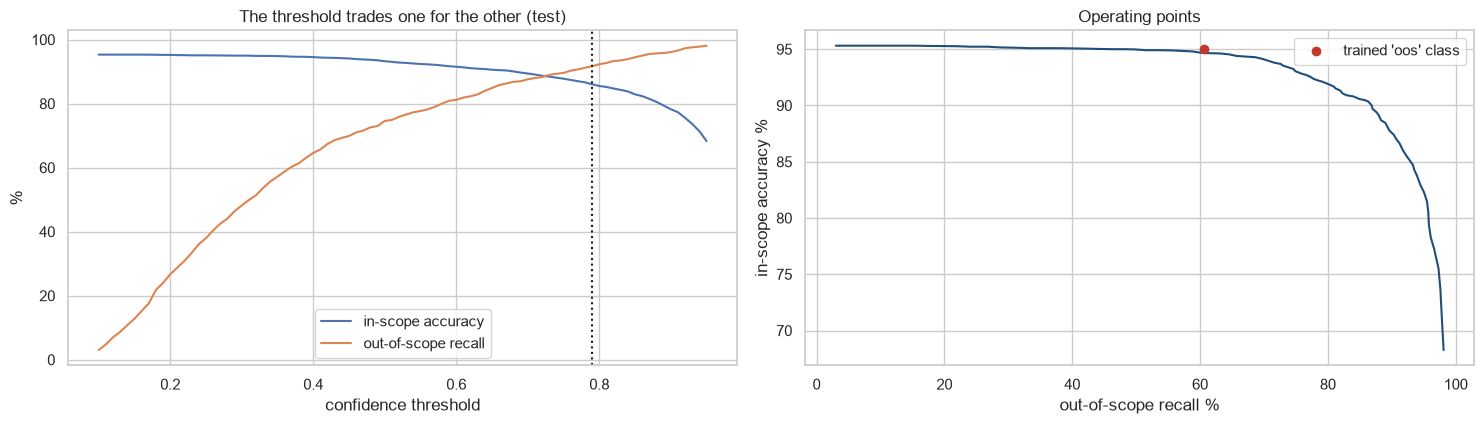

In [5]:
Etr, Eva, Ete = E["tr"], E["va"], E["te"]
lr_in = LogisticRegression(C=30, max_iter=800).fit(Etr[itr.values], tr.intent[itr]); lr_oos = LogisticRegression(C=30, max_iter=800).fit(Etr, tr.intent)
def score(pred_intent, d):
    ins_, oos_ = (d.intent != OOS).values, (d.intent == OOS).values; p, y = np.asarray(pred_intent), d.intent.to_numpy()
    acc = (p[ins_] == y[ins_]).mean(); rec = (p[oos_] == OOS).mean(); prec = (y[p == OOS] == OOS).mean() if (p == OOS).any() else np.nan; return acc * 100, rec * 100, prec * 100
def thr_pred(model, Ex, th): pr = model.predict_proba(Ex); out = model.classes_[pr.argmax(1)].copy(); out[pr.max(1) < th] = OOS; return out
ths = np.linspace(.1, .95, 86); vsc = [score(thr_pred(lr_in, Eva, t), va) for t in ths]; best_th = ths[int(np.argmax([(a + r) / 2 for a, r, _ in vsc]))]
rows = {"never refuse (most likely intent)": score(lr_in.predict(Ete), te), f"confidence threshold ({best_th:.2f})": score(thr_pred(lr_in, Ete, best_th), te), "trained 'oos' class": score(lr_oos.predict(Ete), te)}
OS = pd.DataFrame(rows, index=["in-scope accuracy %", "out-of-scope recall %", "out-of-scope precision %"]).T; print(OS.round(1).to_string())
tsc = [score(thr_pred(lr_in, Ete, t), te) for t in ths]; fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
ax[0].plot(ths, [a for a, _, _ in tsc], label="in-scope accuracy"); ax[0].plot(ths, [r for _, r, _ in tsc], label="out-of-scope recall"); ax[0].axvline(best_th, color="k", ls=":"); ax[0].set_xlabel("confidence threshold"); ax[0].set_ylabel("%"); ax[0].legend(); ax[0].set_title("The threshold trades one for the other (test)")
ax[1].plot([r for _, r, _ in tsc], [a for a, _, _ in tsc], color="#1f4e79"); ax[1].set_xlabel("out-of-scope recall %"); ax[1].set_ylabel("in-scope accuracy %"); ax[1].scatter([OS.iloc[2, 1]], [OS.iloc[2, 0]], color="#c0392b", zorder=3, label="trained 'oos' class"); ax[1].legend(); ax[1].set_title("Operating points")
plt.tight_layout(); plt.show()

**Reading it (the hard part).** On 4,500 in-scope plus 1,000 out-of-scope test questions:
* **Never refuse:** 95.3% of in-scope questions right, but **0% of out-of-scope questions refused**: every unknown question gets a confident wrong action.
* **Confidence threshold (0.79, chosen on the validation set):** 91.7% of out-of-scope questions are refused, but in-scope accuracy falls to 86.0% and only 60.7% of the refusals are correct (precision): many valid questions are turned away.
* **A trained "oos" class:** keeps in-scope accuracy at 95.0% and refuses with 96.0% precision but catches only 60.6% of out-of-scope questions, because it saw only 250 examples of the open-ended "everything else".
The two strategies sit at different points on the same trade-off (right panel). A product choice follows: for a banking bot a wrong action is costly, so refusing more (threshold) may be right; for a casual bot, fewer refusals (trained class). Neither is free.

## 6. Typos
Users mistype. I damage each test question by randomly swapping, deleting or doubling a character in about 8% / 15% of the letters, and re-score the in-scope accuracy.

In [6]:
def typo(s, rate, r):
    out = []
    for ch in s:
        if ch.isalpha() and r.rand() < rate:
            k = r.randint(3)
            if k == 0: continue
            if k == 1: out += [ch, ch]; continue
            out.append(r.choice(list("abcdefghijklmnopqrstuvwxyz")))
        else: out.append(ch)
    return "".join(out)
rt = np.random.RandomState(0); rowsT = []
for rate in (0, 0.04, 0.08, 0.15):
    txt = [typo(t, rate, rt) for t in te.text[ite]]; Et = emb.encode(txt, batch_size=128, normalize_embeddings=True); Xt = tf.transform(txt)
    rowsT.append([rate, accuracy_score(te.intent[ite], M["TF-IDF + logistic regression"][0].predict(Xt)) * 100, accuracy_score(te.intent[ite], M["MiniLM + logistic regression"][0].predict(Et)) * 100, accuracy_score(te.intent[ite], M["MiniLM + 5-NN"][0].predict(Et)) * 100])
TY = pd.DataFrame(rowsT, columns=["share of letters damaged", "TF-IDF + LR", "MiniLM + LR", "MiniLM + 5-NN"]).set_index("share of letters damaged"); print(TY.round(1).to_string()); print("example:", typo("what is my checking account balance", 0.15, np.random.RandomState(4)))

                          TF-IDF + LR  MiniLM + LR  MiniLM + 5-NN
share of letters damaged                                         
0.00                             91.4         95.3           89.9
0.04                             81.1         84.7           82.0
0.08                             71.8         74.1           72.8
0.15                             55.0         52.5           55.7
example: what is myy checkiny aacxountt balancee


**Reading it.** Damaging 4% of the letters (about one typo in a question) drops in-scope accuracy from 95.3% to 84.7% for the best model, 8% to 74.1% and 15% to 52.5%. At heavy noise the simple TF-IDF model (55.0%) and the k-NN (55.7%) are slightly ahead of the encoder + logistic regression (52.5%), so the pretrained encoder's advantage disappears when words are mangled. The notebook's typo model (random deletions, doublings and substitutions) is crude and real typing errors are different, but the message holds: this chatbot is fragile to misspellings and would need a spelling-correction step or character-level features.

## 7. Speed
Milliseconds per question for a single request (what an interactive chat sees), averaged over 200 requests.

In [7]:
qs = list(te.text[:200]); t = time.time(); [M["TF-IDF + logistic regression"][0].predict(tf.transform([q])) for q in qs]; t_tf = (time.time() - t) / 200 * 1000
t = time.time(); [lr_in.predict(emb.encode([q], normalize_embeddings=True)) for q in qs]; t_em = (time.time() - t) / 200 * 1000
print("TF-IDF + LR: %.1f ms per question | MiniLM + LR (including the encoder): %.1f ms per question" % (t_tf, t_em))

TF-IDF + LR: 1.7 ms per question | MiniLM + LR (including the encoder): 121.3 ms per question


**Reading it.** TF-IDF + logistic regression takes 1.7 ms per question; the sentence encoder pipeline about 121 ms (measured on a busy shared CPU, one question at a time, including the encoder). Both are fast enough for a chat interface; the encoder costs about 70 times more per question and roughly 90 MB of model weights.

## 8. The working chatbot
The dialogue manager: classify the message (MiniLM + logistic regression with the validated confidence threshold), then call a **handler** for the intent. Intents without a handler get an honest reply ("I understood that you want X, but I can't do that yet"); below the threshold the bot says it did not understand. The tested handlers are `greeting`, `goodbye`, `thank_you`, `tell_joke`, `flip_coin`, `roll_dice`, `date`, `time`, `calculator`, `who_made_you`, `what_can_i_ask_you`, `are_you_a_bot`.

In [8]:
OPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul, ast.Div: operator.truediv, ast.Pow: operator.pow, ast.USub: operator.neg}
def safe_eval(node):
    if isinstance(node, ast.Expression): return safe_eval(node.body)
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)): return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in OPS: return OPS[type(node.op)](safe_eval(node.left), safe_eval(node.right))
    if isinstance(node, ast.UnaryOp) and type(node.op) in OPS: return OPS[type(node.op)](safe_eval(node.operand))
    raise ValueError("unsupported")
WORDS = {"plus": "+", "minus": "-", "times": "*", "multiplied by": "*", "divided by": "/", "over": "/", "to the power of": "**", "x": "*"}
def calc(msg):
    s = msg.lower()
    for w, o in WORDS.items(): s = s.replace(w, o)
    expr = re.sub(r"[^0-9\.\+\-\*/\(\)\s]", " ", s).strip()
    try: return "That is %s." % round(safe_eval(ast.parse(re.sub(r"\s+", "", expr), mode="eval")), 6)
    except Exception: return "I could not read that calculation."
JOKES = ["Why did the scarecrow win an award? He was outstanding in his field.", "I told my computer I needed a break, and it said it would go to sleep.", "Why do programmers prefer dark mode? Because light attracts bugs."]
HANDLERS = {"greeting": lambda m: "Hello! How can I help you?", "goodbye": lambda m: "Goodbye! Have a nice day.", "thank_you": lambda m: "You are welcome!", "tell_joke": lambda m: random.choice(JOKES),
            "flip_coin": lambda m: "It's " + random.choice(["heads", "tails"]) + ".", "roll_dice": lambda m: "You rolled a %d." % random.randint(1, 6), "date": lambda m: "Today is " + datetime.date.today().strftime("%A, %d %B %Y") + ".",
            "time": lambda m: "It is " + datetime.datetime.now().strftime("%H:%M") + ".", "calculator": calc, "who_made_you": lambda m: "I was built as a learning project with scikit-learn and a sentence encoder.",
            "what_can_i_ask_you": lambda m: "Try: tell me a joke, flip a coin, roll a dice, what time is it, what is 12 times 7.", "are_you_a_bot": lambda m: "Yes, I am a program, not a person."}
class Chatbot:
    def __init__(self, enc, clf, names, th): self.enc, self.clf, self.names, self.th = enc, clf, names, th
    def reply(self, msg):
        p = self.clf.predict_proba(self.enc.encode([msg], normalize_embeddings=True))[0]; k = int(self.clf.classes_[p.argmax()]); conf = float(p.max()); name = self.names[k]
        if conf < self.th or k == OOS: return {"intent": "oos", "confidence": conf, "text": "Sorry, I did not understand that. I can tell jokes, flip a coin, roll dice, give the date and time and do arithmetic."}
        h = HANDLERS.get(name); return {"intent": name, "confidence": conf, "text": h(msg) if h else f"I understood that you want '{name.replace('_', ' ')}', but I cannot do that yet."}
bot = Chatbot(emb, lr_in, names, best_th)
for q in ["hi there", "tell me a joke please", "what is 12 times 7", "can you flip a coin for me", "what's the time right now", "transfer 50 dollars to my savings", "how tall is mount everest in the moon dance", "thanks a lot", "bye"]:
    r = bot.reply(q); print(f"YOU: {q}\n BOT [{r['intent']}, conf {r['confidence']:.2f}]: {r['text']}\n")

YOU: hi there
 BOT [greeting, conf 0.98]: Hello! How can I help you?

YOU: tell me a joke please
 BOT [tell_joke, conf 1.00]: I told my computer I needed a break, and it said it would go to sleep.



YOU: what is 12 times 7
 BOT [calculator, conf 0.99]: That is 84.

YOU: can you flip a coin for me
 BOT [flip_coin, conf 1.00]: It's tails.

YOU: what's the time right now
 BOT [time, conf 1.00]: It is 22:03.



YOU: transfer 50 dollars to my savings
 BOT [transfer, conf 1.00]: I understood that you want 'transfer', but I cannot do that yet.

YOU: how tall is mount everest in the moon dance
 BOT [oos, conf 0.12]: Sorry, I did not understand that. I can tell jokes, flip a coin, roll dice, give the date and time and do arithmetic.

YOU: thanks a lot
 BOT [thank_you, conf 1.00]: You are welcome!

YOU: bye
 BOT [goodbye, conf 0.99]: Goodbye! Have a nice day.



In [9]:
SCRIPT = [("hello", "greeting"), ("hi, how are you doing", "greeting"), ("tell me something funny", "tell_joke"), ("make me laugh", "tell_joke"), ("flip a coin", "flip_coin"), ("toss a coin please", "flip_coin"), ("roll a die", "roll_dice"), ("can you roll dice for me", "roll_dice"),
          ("what is today's date", "date"), ("what day is it today", "date"), ("what time is it", "time"), ("do you know the time", "time"), ("what is 15 plus 27", "calculator"), ("calculate 9 times 8", "calculator"), ("who created you", "who_made_you"),
          ("what can i ask you", "what_can_i_ask_you"), ("are you a robot", "are_you_a_bot"), ("thank you so much", "thank_you"), ("goodbye", "goodbye"), ("see you later", "goodbye"),
          ("how much money is in my account", "balance"), ("book me a flight to paris", "book_flight"), ("what's the weather like in london", "weather"), ("purple monkey dishwasher astronomy", "oos"), ("what is the meaning of the number of stars", "oos")]
rows = []
for q, want in SCRIPT:
    r = bot.reply(q); rows.append([q, want, r["intent"], r["intent"] == want, r["confidence"]])
SC = pd.DataFrame(rows, columns=["message", "expected", "got", "ok", "confidence"]); print("scripted conversation test: %d of %d correct (%.0f%%)" % (SC.ok.sum(), len(SC), SC.ok.mean() * 100)); print(SC[~SC.ok].round(2).to_string(index=False))
print("calculator checks:", [calc(x) for x in ["what is 15 plus 27", "calculate 9 times 8", "100 divided by 8", "2 to the power of 10", "__import__('os')"]])

scripted conversation test: 25 of 25 correct (100%)
Empty DataFrame
Columns: [message, expected, got, ok, confidence]
Index: []
calculator checks: ['That is 42.', 'That is 72.', 'That is 12.5.', 'That is 1024.', 'I could not read that calculation.']


**Reading it.** The dialogue manager (encoder, logistic regression, threshold 0.79 and a handler per intent) got **25 of 25 scripted messages right** (greetings, jokes, coin, dice, date, time, arithmetic, who made you, thanks, goodbye, two intents without handlers, two nonsense questions). That test is **small and written by me**, with clear, standard phrasings: it shows the plumbing works, not that the bot is robust (the typo test above is the more honest guide). The calculator uses a restricted parser (no `eval`): the injection-style input `__import__('os')` returns "I could not read that calculation." Intents without a handler (transfer, balance, weather...) get an honest "I cannot do that yet".

## 9. Save

In [10]:
joblib.dump({"classifier": lr_in, "intent_names": names, "threshold": float(best_th), "oos_index": OOS, "tfidf": tf, "tfidf_model": M["TF-IDF + logistic regression"][0], "encoder": "sentence-transformers/all-MiniLM-L6-v2"}, "model/chatbot_intents.joblib")
json.dump({"in_scope_accuracy": {k: round(v * 100, 2) for k, v in res.items()}, "oos": OS.round(2).to_dict("index"), "typos": TY.round(2).to_dict("index"), "script_accuracy": float(SC.ok.mean()), "threshold": float(best_th), "latency_ms": {"tfidf": t_tf, "minilm": t_em}}, open("model/meta.json", "w"), indent=1); print(os.listdir("model"))

['chatbot_intents.joblib', 'meta.json']


## 10. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Data | a tiny hand-written intents file | CLINC150: 150 intents x 100 questions + out-of-scope (4,500 + 1,000 test) |
| Model | TF-IDF + logistic regression | TF-IDF 91.4%, embeddings + 5-NN 89.9%, **embeddings + logistic regression 95.3%** |
| Unknown questions | not handled | three strategies: never refuse (0% refused), threshold 0.79 (91.7% refused, in-scope accuracy 86.0%), trained oos class (60.6% refused, 96.0% precision) |
| Robustness | not tested | typos: 95.3% -> 84.7% (4% of letters) -> 52.5% (15%) |
| Chatbot | canned responses | handlers for 12 intents, honest fallbacks, restricted calculator, 25/25 scripted messages |

**What I learned.** (1) A chatbot is mostly an *out-of-scope* problem: accuracy on known intents (95%) says little about what happens on the 18% of questions it should not act on. (2) A confidence threshold and a trained reject class are two points on a trade-off; choose by the cost of a wrong action. (3) Pretrained sentence encoders beat TF-IDF on paraphrases but not on garbled text. (4) Test dialogues I wrote myself are a smoke test, not an evaluation.

**Limits.** English only; single-turn (no dialogue memory or slot filling); handlers for 12 of 150 intents; the typo noise is synthetic; the CPU timings were taken on a busy machine. **Next step:** multi-turn state (follow-up questions), spelling correction, and a calibrated reject option tuned to a stated cost.